# Experiment 18: Perceptron based Iris Classification
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Implement **Perceptron** based **Iris classification**.

## Algorithm
For each training sample `(x, t)` with output `o = step(w.x + b)`:

`w <- w + eta (t - o) x`,  `b <- b + eta (t - o)`

The perceptron converges only for **linearly separable** classes, so first a binary problem (*setosa* vs *versicolor*) is solved from scratch using two features, then scikit-learn's Perceptron handles all 3 classes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()
mask = iris.target < 2                                # setosa (0) vs versicolor (1)
X = iris.data[mask][:, [2, 3]]                         # petal length, petal width
y = iris.target[mask]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (80, 2) | Test: (20, 2)


In [2]:
class Perceptron_Scratch:
    def __init__(self, lr=0.1, epochs=50):
        self.lr, self.epochs = lr, epochs

    def fit(self, X, y):
        self.w = np.zeros(X.shape[1]); self.b = 0.0
        self.errors = []
        for ep in range(self.epochs):
            err = 0
            for xi, ti in zip(X, y):
                o = 1 if (xi @ self.w + self.b) >= 0 else 0
                update = self.lr * (ti - o)
                self.w += update * xi
                self.b += update
                err += int(update != 0)
            self.errors.append(err)
            if err == 0:
                print(f'Converged after {ep + 1} epochs (0 misclassifications).')
                break
        return self

    def predict(self, X):
        return (X @ self.w + self.b >= 0).astype(int)

p = Perceptron_Scratch(lr=0.1, epochs=50).fit(X_train, y_train)
print('Weights:', p.w.round(3), '| Bias:', round(p.b, 3))
print('Train accuracy:', (p.predict(X_train) == y_train).mean())
print('Test accuracy :', (p.predict(X_test) == y_test).mean())

Converged after 2 epochs (0 misclassifications).
Weights: [0.12 0.14] | Bias: -0.4
Train accuracy: 1.0
Test accuracy : 1.0


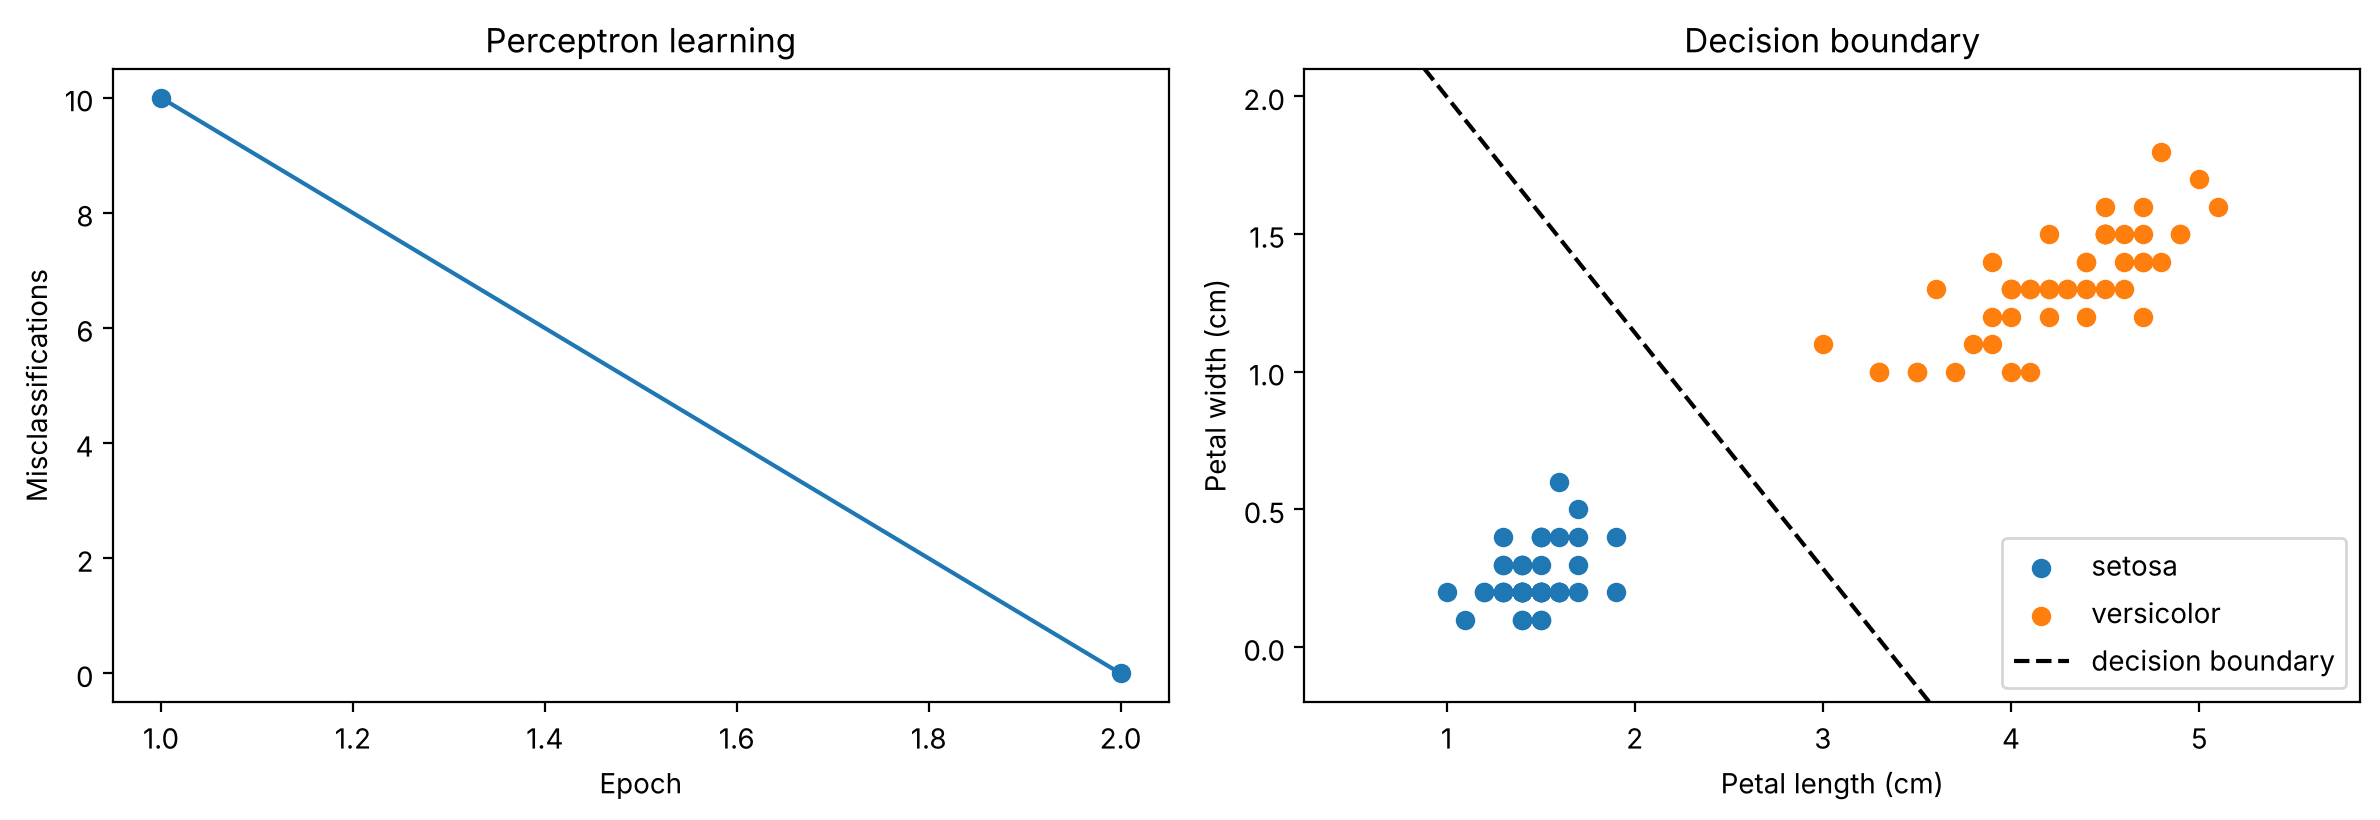

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(range(1, len(p.errors) + 1), p.errors, marker='o')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Misclassifications'); ax[0].set_title('Perceptron learning')

for cls, col in zip([0, 1], ['tab:blue', 'tab:orange']):
    ax[1].scatter(X[y == cls, 0], X[y == cls, 1], c=col, label=iris.target_names[cls])
xs = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 100)
ax[1].plot(xs, -(p.w[0] * xs + p.b) / p.w[1], 'k--', label='decision boundary')
ax[1].set_ylim(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3)
ax[1].set_xlabel('Petal length (cm)'); ax[1].set_ylabel('Petal width (cm)'); ax[1].legend()
ax[1].set_title('Decision boundary'); plt.tight_layout(); plt.show()

### All three Iris classes with scikit-learn's Perceptron (one-vs-rest)

3-class Perceptron test accuracy: 0.8667 

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.88      0.70      0.78        10
   virginica       0.75      0.90      0.82        10

    accuracy                           0.87        30
   macro avg       0.88      0.87      0.87        30
weighted avg       0.88      0.87      0.87        30



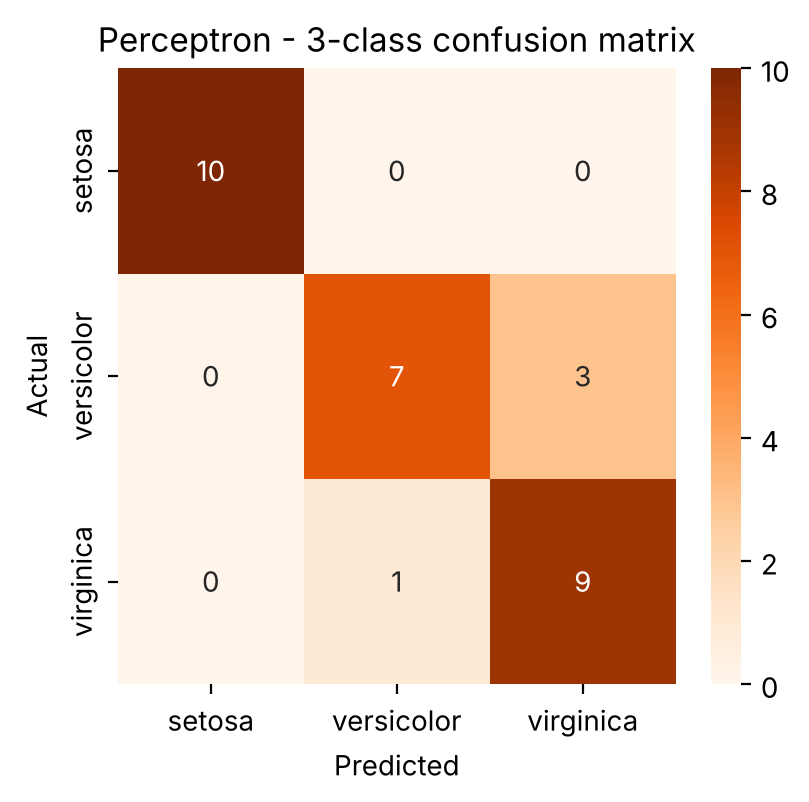

In [4]:
from sklearn.linear_model import Perceptron
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Xa, ya = iris.data, iris.target
Xtr, Xte, ytr, yte = train_test_split(Xa, ya, test_size=0.2, random_state=42, stratify=ya)
sc = StandardScaler().fit(Xtr)
clf = Perceptron(max_iter=1000, eta0=0.1, random_state=42).fit(sc.transform(Xtr), ytr)
pred = clf.predict(sc.transform(Xte))
print('3-class Perceptron test accuracy:', round(accuracy_score(yte, pred), 4), '\n')
print(classification_report(yte, pred, target_names=iris.target_names))

plt.figure(figsize=(4.5, 4))
sns.heatmap(confusion_matrix(yte, pred), annot=True, fmt='d', cmap='Oranges',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Perceptron - 3-class confusion matrix'); plt.show()

## Result
For the linearly separable *setosa vs versicolor* problem the perceptron converges to zero errors and learns a straight decision boundary. For all three classes a single-layer perceptron is less accurate, because *versicolor* and *virginica* are not perfectly linearly separable - which motivates multi-layer networks (Experiment 4).